# Miniproyecto 1

## Clasificación de MRI con Redes Neuronales Convolucionales para Tumores cerebrales



La resonancia magnética (MRI) desempeña un papel fundamental en la detección y clasificación de los diferentes tipos de tumores cerebrales. La aplicación de redes neuronales convolucionales (CNN) ha incrementado notablemente la precisión en la interpretación de estos volúmenes, al ser entrenadas para reconocer patrones y características distintivas asociadas a cada tipo de tumor. Las resonancias magnéticas (MRI) generan volúmenes tridimensionales compuestos por múltiples capas, donde cada una corresponde a una imagen bidimensional del tejido analizado. Procesar un volumen completo implica manejar una gran cantidad de datos simultáneamente, lo que puede ser computacionalmente costoso y requerir considerable tiempo y recursos. Para este proyecto se trabajará exclusivamente con imágenes individuales extraídas de las capas de los MRI, en lugar de procesar el volumen completo. Esta estrategia simplifica la tarea al transformar el problema en una clasificación de imágenes bidimensionales, reduciendo significativamente la carga computacional.

Redes Neuronales Convolucionales

Las CNN son especialmente adecuadas para el análisis de imágenes debido a su capacidad para captar características locales a través de convoluciones. Estas redes pueden ser entrenadas para clasificar las imágenes extraídas de los MRI en cuatro categorías: glioma, meningioma, pituitary (hipófisis) y tejido sano. Por ejemplo:

- Glioma: Detecta masas anómalas con bordes irregulares y heterogeneidad en el tejido cerebral.
- Meningioma: Identifica tumores bien delimitados originados en las meninges.
- Pituitary: Clasifica adenomas hipofisarios en la región selar.
- Tejido sano: Diferencia el tejido cerebral normal sin anomalías presentes.

Procesamiento de Imágenes

El procesamiento de imágenes mediante redes neuronales convolucionales (CNN) involucra múltiples capas de convolución, activación y pooling, que permiten extraer y analizar características relevantes de las imágenes. Estas técnicas facilitan una distinción precisa entre distintos tipos de tumores y el tejido sano, mejorando la exactitud del diagnóstico médico.
Ventajas y Aplicaciones
Implementar CNN para la clasificación de las imágenes extraídas de los MRI ofrece varias ventajas:
- Eficiencia en el diagnóstico: Acelera el proceso de evaluación de imágenes, permitiendo a los profesionales médicos enfocarse en otros aspectos del tratamiento.
- Consistencia en la clasificación: Proporciona una clasificación uniforme y precisa, reduciendo la variabilidad entre evaluadores.
- Asistencia para profesionales menos experimentados: Ofrece una herramienta valiosa para radiólogos en formación o con menos experiencia.
- Mejora en la calidad del diagnóstico: Optimiza la detección temprana y el tratamiento adecuado de diferentes tipos de cáncer cerebral.

A. Objetivo
- Desarrollar un método basado en redes neuronales convolucionales que permita clasificar con exactitud imágenes extraídas de MRIs en una de las 4 categorías.

B. Conjunto de datos
-Los datos corresponden a un dataset de 7023 imágenes extraídas de MRIs tomados desde distintos ángulos y disponibles para dominio público. El dataset es accesible en el siguiente enlace.

C. Actividades por realizar
1. Preparación de las imágenes para el entrenamiento y prueba del modelo. Construya un pipeline para cargar las imágenes y dividirlas en conjuntos de entrenamiento y prueba.
2. Desarrollo de la arquitectura de red neuronal convolucional para clasificación de las imágenes de MRI en una de las 4 categorías. La arquitectura es de libre elección, se recomienda utilizar bloques de convolución y max pooling o usar redes existentes y hacerles finetunning para este problema.

<a id="inicio"></a>
# Contenido del cuaderno:

A continuación se realiza el cargue, preparación de las imagenes médicas y construcción de los siguientes tres modelos:
- [1. Cargue de librerias y funciones necesarias](#seccion-1)
- [2. Cargue y preparación de imagenes.](#seccion-2)
- [3. Definición del modelo base personalizado con capas convolucionales apiladas.](#seccion-3)
- [4. Utilización de red pre-entrenada](#seccion-4)
- [5. Utilización de red pre-entrenada con fine-tunning.](#seccion-5)
- [6. Tabla comparativa de los 3 modelos](#seccion-6)
- [7. Conclusiones](#seccion-7)

Finalmente se comparan los resultados obtenidos y se generan conclusiones al respecto.

<a id="seccion-1"></a>
# 1. Cargue de librerias y funciones necesarias reutilizables

In [1]:
# Se importan librerias necesarias
import zipfile
import torch
import torch.nn as nn
import torch.optim as optim
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report

### Inicialización de semillas.

In [2]:
SEED = 0

def seed_everything(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    return seed


SEED = seed_everything(42)

### Uso dispositivo de cómputo.

In [3]:
# Dispositivo de cómputo (usa GPU si está disponible de lo contrario CPU)
if torch.cuda.is_available():
    print("Nombre de la GPU:", torch.cuda.get_device_name(0))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Usando dispositivo: {device}')

Nombre de la GPU: NVIDIA GeForce RTX 5070 Ti
Usando dispositivo: cuda


### Descomprimir archivo .zip con imágenes:

In [4]:
ZIP_PATH = 'Brain_Tumor_MRI_Dataset.zip'
extracted_path = './Brain_Tumor_Data'

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(extracted_path)

print("¡Descompresión exitosa!")

¡Descompresión exitosa!


### Pipeline de preparación de imágenes y separación en entrenamiento y test.

In [5]:
def prepare_data_pipeline(data_dir='./Brain_Tumor_Data', img_size=128, train_split=0.7, val_split=0.15, seed=SEED):
    """
    Carga el dataset de imágenes, aplica las transformaciones y realiza
    la división en entrenamiento, validación y prueba.

    Parámetros:
        data_dir (str): Ruta de la carpeta principal que contiene las subcarpetas con las clases.
        img_size (int): Tamaño al que se redimensionarán las imágenes (ej. 128 para 128x128).
        train_split (float): Proporción de datos para entrenamiento (ej. 0.7 para 70%).
        val_split (float): Proporción de datos para validación (ej. 0.15 para 15%).
                           El resto queda para prueba.
        seed (int): Semilla aleatoria para asegurar la reproducibilidad en la división.

    Salida:
        dataset: Dataset completo.
        train_dataset, val_dataset, test_dataset: Subconjuntos listos para crear los DataLoaders.
        class_names (list): Lista con los nombres de las 4 clases de tumores encontradas.
    """

    # 1. Definir las transformaciones (Redimensionar tamaño de imágenes y convertir a tensor numérico)
    transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor()
    ])

    # 2. Cargar el dataset completo desde las carpetas usando ImageFolder
    dataset = datasets.ImageFolder(root=data_dir, transform=transform)

    print(f"Clases encontradas: {dataset.classes}")
    print(f"Total de imágenes: {len(dataset)}")

    # 3. Calcular los tamaños para la división (Entrenamiento, Validación y Prueba)
    train_size = int(train_split * len(dataset))
    val_size = int(val_split * len(dataset))
    test_size = len(dataset) - train_size - val_size

    # 4. Fijar una semilla para que la división aleatoria sea reproducible siempre
    generator = torch.Generator().manual_seed(seed)

    # 5. Dividir el dataset en entrenamiento, validación y prueba
    train_dataset, val_dataset, test_dataset = random_split(
        dataset, [train_size, val_size, test_size], generator=generator
    )

    print(f"Imágenes para entrenamiento: {len(train_dataset)}")
    print(f"Imágenes para validación: {len(val_dataset)}")
    print(f"Imágenes para prueba: {len(test_dataset)}")

    return dataset, train_dataset, val_dataset, test_dataset, dataset.classes

### Conteo de muestras por clase en conjuntos de entrenamiento y test.

La siguiente función tiene como objetivo contar la cantidad de imagenes por clase en el dataset completo, asi como en los conjuntos de entrenamiento, validación y test:

In [6]:
def analyze_class_distribution(dataset, subsets):
    """
    Muestra cuántas imágenes de cada clase hay en el dataset completo
    y en cada subconjunto entrenamiento, validación y prueba.
    """
    print("--- Dataset completo ---")
    for i, clase in enumerate(dataset.classes):
        print(f"Clase '{clase}': {dataset.targets.count(i)} imágenes")

    for nombre, subset in subsets.items():
        etiquetas = [dataset.targets[idx] for idx in subset.indices]
        print(f"\n--- {nombre} ({len(subset)} imágenes) ---")
        for i, clase in enumerate(dataset.classes):
            print(f"Clase '{clase}': {etiquetas.count(i)} imágenes")

### Visualización de imagenes de entrenamiento por clase.

La siguiente función visualiza una imagen por clase del conjunto de datos que se le pase por parámetro.

In [7]:
def visualize_brain_tumor_instances(dataset):
    """
    Visualiza una instancia de cada categoría del dataset de tumores cerebrales.
    Parámetro:
    dataset = train_dataset o el dataset completo de PyTorch
    """
    # Obtener la lista de nombres de las clases
    classes = dataset.classes if hasattr(dataset, 'classes') else dataset.dataset.classes
    num_classes = len(classes)

    fig, axes = plt.subplots(nrows=1, ncols=num_classes, figsize=(15, 5))

    # Diccionario para almacenar una imagen por cada clase encontrada
    found_classes = {}

    # Buscar una muestra por cada etiqueta
    for img, label in dataset:
        if label not in found_classes:
            found_classes[label] = img
            if len(found_classes) == num_classes:
                break

    # Graficar cada una
    for i in range(num_classes):
        img_tensor = found_classes[i]

        # PyTorch maneja los tensores como (C, H, W).
        # Matplotlib necesita (H, W, C) para color o (H, W) para escala de grises.
        if img_tensor.shape[0] == 3: # Si es RGB
            img_display = img_tensor.permute(1, 2, 0).numpy()
        else: # Si es escala de grises
            img_display = img_tensor.squeeze(0).numpy()

        axes[i].imshow(img_display, cmap='gray' if img_tensor.shape[0] == 1 else None)
        axes[i].set_title(f"{classes[i]}")
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

In [8]:
def visualizar_modelo(modelo, input_shape, nombre_archivo='model.png'):
    """
    Genera un diagrama simple de bloques apilados que representa la arquitectura
    del modelo, análogo a plot_model de Keras, y lo guarda como imagen.

    Parámetros de entrada:
    modelo = modelo de PyTorch construido con nn.Sequential
    input_shape = forma de una instancia de entrada, sin incluir la dimensión de lote (batch)
    nombre_archivo = nombre del archivo de imagen donde se guarda el diagrama

    Parámetros de salida:
    Gráfica con el diagrama de bloques del modelo.
    """
    parametros = list(modelo.parameters())
    dispositivo = parametros[0].device if parametros else 'cpu'
    entrada = torch.zeros(1, *input_shape, device=dispositivo)

    bloques = [('Entrada', tuple(entrada.shape))]
    salida = entrada
    with torch.no_grad():
        for nombre, capa in modelo.named_children():
            salida = capa(salida)
            bloques.append((capa.__class__.__name__, tuple(salida.shape)))

    fig, ax = plt.subplots(figsize=(4, 1.4 * len(bloques)))
    for i, (etiqueta, forma) in enumerate(bloques):
        y = len(bloques) - i
        ax.add_patch(plt.Rectangle((0, y - 0.4), 3, 0.8, facecolor='#5a2ff4', alpha=0.15, edgecolor='#5a2ff4'))
        ax.text(1.5, y, f'{etiqueta}\n{forma}', ha='center', va='center', fontsize=9)
        if i > 0:
            ax.annotate('', xy=(1.5, y + 0.4), xytext=(1.5, y + 0.6),
                        arrowprops=dict(arrowstyle='->', color='#5a2ff4'))
    ax.set_xlim(-0.5, 3.5)
    ax.set_ylim(0, len(bloques) + 1)
    ax.axis('off')
    plt.tight_layout()
    plt.savefig(nombre_archivo, dpi=150)
    plt.show()

### Función de entrenamiento para cualquier modelo

In [9]:
def train_model(model, train_loader, val_loader, optimizer,
                epochs=10, criterion=None, device='cpu'):
    """
    Entrena `model` durante `epochs` épocas usando un DataLoader de entrenamiento,
    evaluando al final de cada época sobre el DataLoader de validación.

    Parámetros de entrada:
    model = modelo de PyTorch (nn.Module)
    train_loader = DataLoader con los datos de entrenamiento
    val_loader = DataLoader con los datos de validación
    optimizer = optimizador de torch.optim ya asociado a los parámetros de `model`
    epochs = número de épocas de entrenamiento
    criterion = función de pérdida (por defecto nn.CrossEntropyLoss)
    device = dispositivo de ejecución ('cuda' o 'cpu')

    Salida:
    history = diccionario con las llaves 'accuracy', 'val_accuracy', 'loss', 'val_loss'
    """
    if criterion is None:
        criterion = nn.CrossEntropyLoss()

    model.to(device)
    history = {'accuracy': [], 'val_accuracy': [], 'loss': [], 'val_loss': []}

    for epoch in range(epochs):
        # 1. Fase de Entrenamiento
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            # Vaciar los gradientes anteriores
            optimizer.zero_grad()

            # Propagación hacia adelante (Forward pass)
            outputs = model(images)
            loss = criterion(outputs, labels)

            # Propagación hacia atrás y optimización (Backward pass & Step)
            loss.backward()
            optimizer.step()

            # Métricas de entrenamiento
            running_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += images.size(0)

        train_loss, train_acc = running_loss / total, correct / total

        # 2. Fase de Evaluación (usando tu función evaluate_model previa)
        val_loss, val_acc = evaluate_model(model, val_loader, criterion=criterion, device=device)

        # 3. Guardar métricas en el historial
        history['accuracy'].append(train_acc)
        history['val_accuracy'].append(val_acc)
        history['loss'].append(train_loss)
        history['val_loss'].append(val_loss)

        # Imprimir progreso por época
        print(f"Epoch {epoch + 1}/{epochs} - loss: {train_loss:.4f} - accuracy: {train_acc:.4f} "
              f"- val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}")

    return history

In [10]:
def resumen_modelo(modelo, input_shape):
    """
    Imprime un resumen del modelo, al estilo de Keras: para cada capa de nivel
    superior muestra su tipo, la forma de salida y su número de parámetros
    entrenables.

    Parámetros de entrada:
    modelo = modelo de PyTorch construido con nn.Sequential
    input_shape = forma de una instancia de entrada, sin incluir la dimensión de lote (batch)

    Parámetros de salida:
    Impresión en pantalla con el resumen del modelo.
    """
    parametros = list(modelo.parameters())
    dispositivo = parametros[0].device if parametros else 'cpu'
    entrada = torch.zeros(1, *input_shape, device=dispositivo)

    filas = []
    total_parametros = 0
    salida = entrada
    with torch.no_grad():
        for nombre, capa in modelo.named_children():
            salida = capa(salida)
            n_parametros = sum(p.numel() for p in capa.parameters())
            total_parametros += n_parametros
            filas.append((f'{nombre} ({capa.__class__.__name__})', tuple(salida.shape), n_parametros))

    ancho_nombre = max(len(f[0]) for f in filas) + 2
    print('_' * 65)
    print(f"{'Capa (tipo)':<{ancho_nombre}}{'Forma de salida':<22}{'Parámetros':>10}")
    print('=' * 65)
    for nombre, forma, n_parametros in filas:
        print(f"{nombre:<{ancho_nombre}}{str(forma):<22}{n_parametros:>10,}")
    print('=' * 65)
    print(f'Total de parámetros: {total_parametros:,}')
    print('_' * 65)

### Función de pérdida.

In [11]:
def evaluate_model(model, data_loader, criterion=None, device='cpu'):
    """
    Evalúa `model` sobre un DataLoader y calcula la pérdida y precisión promedio.


    Parámetros de entrada:
    model = modelo de PyTorch (nn.Module)
    data_loader = DataLoader de PyTorch (Puede ser val_loader o test_loader)
    criterion = función de pérdida (por defecto nn.CrossEntropyLoss)
    device = dispositivo de ejecución ('cuda' o 'cpu')

    Salida:
    loss = pérdida promedio
    accuracy = precisión promedio (en porcentaje o fracción, aquí en fracción 0.0 - 1.0)
    """
    if criterion is None:
        criterion = nn.CrossEntropyLoss()

    model.eval() # Poner el modelo en modo evaluación
    total_loss, correct, total = 0.0, 0, 0

    # Desactivar el cálculo de gradientes para ahorrar memoria y acelerar
    with torch.no_grad():
        for images, labels in data_loader:
            # Mover los datos al dispositivo correspondiente (GPU o CPU)
            images = images.to(device)
            labels = labels.to(device)

            # Pasar los datos por el modelo
            outputs = model(images)

            # Calcular la pérdida del lote
            loss = criterion(outputs, labels)

            # Acumular la pérdida ponderada por el tamaño del lote
            total_loss += loss.item() * images.size(0)

            # Contar predicciones correctas
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += images.size(0)

    # Calcular promedios finales
    avg_loss = total_loss / total
    accuracy = correct / total

    return avg_loss, accuracy

### Función de visualización de entrenamiento vs validación

In [12]:
def visualization_history(resultsFit):
    """
    Esta función grafica las curvas de precisión a lo largo de las épocas de entrenamiento
    para el conjunto de prueba como el de validación.
    Parámetros:
    resultsFit = historial de entrenamiento (diccionario con las llaves 'accuracy',
    'val_accuracy', 'loss', 'val_loss')
    Salida:
    Gráfica de la precisión en validación y prueba.
    """
    # Llamado al entrono de la gráfica y fijar tamaño de visualización
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Graficar la presición de la historia en entrenamiento
    axes[0].plot(range(len(resultsFit['accuracy'])), resultsFit['accuracy'],
           '#5a2ff4', linestyle = "-", marker = "o",
           label='Accuracy entrenamiento', lw = 3)

    # Graficar la presición de la historia en validación
    axes[0].plot(range(len(resultsFit['val_accuracy'])), resultsFit['val_accuracy'],  '#60d13e',
           label='Accuracy validación', linestyle = '-', marker = 'o', lw = 3)

    # Umbral 90% de precisión
    #axes[0].plot(range(len(resultsFit['val_accuracy'])), 0.9*np.ones(len(resultsFit['val_accuracy'])),
    #           'red', lw = 3, label = 'Umbral')

    # Títulos de los ejes
    axes[0].set_xlabel('Época',fontsize=16)
    axes[0].set_ylabel(r'Accuracy',fontsize=16)
    axes[0].set_ylim(top=1) # Límite de la grafica
    axes[0].grid()      # Activar la cuadricula
    axes[0].legend(fontsize=14,loc = 'lower right')   # Establecer la legenda


    # Graficar la pérdida de la historia en entrenamiento
    axes[1].plot(range(len(resultsFit['loss'])), resultsFit['loss'],
           '#5a2ff4', linestyle = "-", marker = "o",
           label='Pérdida entrenamiento', lw = 3)

    # Graficar la presición de la historia en validación
    axes[1].plot(range(len(resultsFit['val_loss'])), resultsFit['val_loss'],  '#60d13e',
           label='Pérdida validación', linestyle = '-', marker = 'o', lw = 3)

    # Títulos de los ejes
    axes[1].set_xlabel('Época',fontsize=16)
    axes[1].set_ylabel(r'Pérdida',fontsize=16)
    axes[1].grid()      # Activar la cuadricula
    axes[1].legend(fontsize=14,loc = 'upper right')   # Establecer la legenda


    plt.tight_layout() # Ajusta automáticamente el diseño de la figura
    plt.show()

### Función para generar la matriz de confución.

Se usará una sola vez en cada modelo para evaluar su rendimiento con datos no vistos, el conjunto de test no se usa para decidir nada, unicamente se tomará como comparativa.

In [13]:
def evaluate_and_report_model(model, test_loader, device, class_names=['Glioma', 'Healthy', 'Meningioma', 'Pituitary']):
    """
    Evalúa el modelo entrenado utilizando el conjunto de prueba,
    genera la matriz de confusión visual con Seaborn e imprime el reporte
    de clasificación detallado (Precision, Recall, F1-Score).
    """
    # 1. Asegurar que el modelo está en modo evaluación
    model.eval()
    all_preds = []
    all_labels = []

    # 2. Recorrer todo el conjunto de prueba sin calcular gradientes
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)

            # Obtener la clase con mayor puntaje (predicción)
            preds = outputs.argmax(dim=1)

            # Guardar predicciones y etiquetas reales pasándolas a la CPU
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    # 3. Calcular la matriz de confusión
    cm = confusion_matrix(all_labels, all_preds)

    # 4. Graficar la matriz de confusión con Seaborn
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)

    plt.title('Matriz de Confusión - Tumores Cerebrales', fontsize=14, pad=15)
    plt.xlabel('Predicción del Modelo', fontsize=12)
    plt.ylabel('Etiqueta Real (Ground Truth)', fontsize=12)
    plt.tight_layout()
    plt.show()

    # 5. Imprimir métricas detalladas por clase (Precision, Recall, F1-Score)
    print("\n--- Reporte de Clasificación Detallado ---")
    print(classification_report(all_labels, all_preds, target_names=class_names))

    # 6. Devolver las métricas para construir la tabla comparativa
    return classification_report(all_labels, all_preds, target_names=class_names, output_dict=True)

[⬆ Volver al índice](#inicio)

<a id="seccion-2"></a>
# 2. Cargue y preparación de imagenes.

### Ejecutar pipeline de preparación de imágenes y análisis de distribución.

In [14]:
# 1. Ejecutar el pipeline de datos
dataset, train_dataset, val_dataset, test_dataset, class_names = prepare_data_pipeline(
    data_dir='./Brain_Tumor_Data',
    img_size=128,
    train_split=0.7,
    val_split=0.15
)

# 2. Ejecutar la función de análisis de distribución
analyze_class_distribution(dataset, {
    "Entrenamiento": train_dataset,
    "Validación": val_dataset,
    "Prueba": test_dataset,
})

Clases encontradas: ['glioma', 'healthy', 'meningioma', 'pituitary']
Total de imágenes: 7023
Imágenes para entrenamiento: 4916
Imágenes para validación: 1053
Imágenes para prueba: 1054
--- Dataset completo ---
Clase 'glioma': 1621 imágenes
Clase 'healthy': 2000 imágenes
Clase 'meningioma': 1645 imágenes
Clase 'pituitary': 1757 imágenes

--- Entrenamiento (4916 imágenes) ---
Clase 'glioma': 1128 imágenes
Clase 'healthy': 1397 imágenes
Clase 'meningioma': 1146 imágenes
Clase 'pituitary': 1245 imágenes

--- Validación (1053 imágenes) ---
Clase 'glioma': 257 imágenes
Clase 'healthy': 294 imágenes
Clase 'meningioma': 255 imágenes
Clase 'pituitary': 247 imágenes

--- Prueba (1054 imágenes) ---
Clase 'glioma': 236 imágenes
Clase 'healthy': 309 imágenes
Clase 'meningioma': 244 imágenes
Clase 'pituitary': 265 imágenes


Las anteriores cifras muestran que no hay desbalanceo de clases, ya que la cantidad de imagenes de las diferentes clases en el dataset completo, en el conjunto de entrenamiento, validación y en el conjunto de test son muy similiras y no representan un desbalance alto.

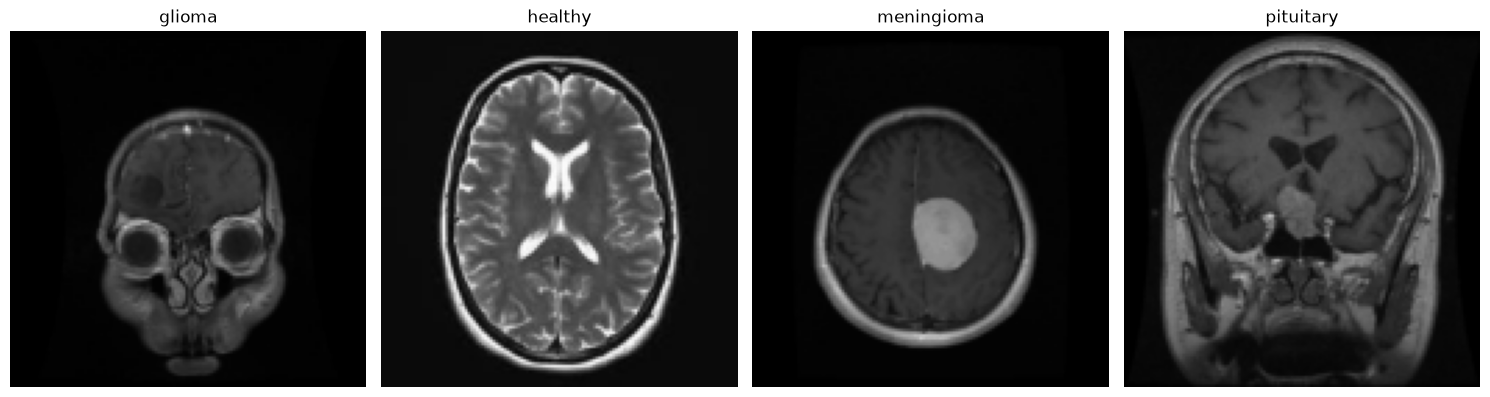

In [15]:
# Visualizamos una imagen por clase del conjunto de entrenamiento
visualize_brain_tumor_instances(train_dataset)

### Verificación tamaño de las imágenes.

In [16]:
# Tomar la primera imagen del dataset de entrenamiento
imagen_ejemplo, etiqueta = train_dataset[0]

print("Forma (shape) de la imagen:", imagen_ejemplo.shape)
print("Número de canales:", imagen_ejemplo.shape[0])
print("Alto y Ancho:", imagen_ejemplo.shape[1], "x", imagen_ejemplo.shape[2])

Forma (shape) de la imagen: torch.Size([3, 128, 128])
Número de canales: 3
Alto y Ancho: 128 x 128


Lo anterior significa que las imagenes estan en formato RGB (3 canales) y tienen 128 pixeles de alto por 128 pixeles de ancho conforme al redimensionamiento realizado previamente en el pipeline de preparación.

<a id="seccion-3"></a>
# 3. Definición del modelo base personalizado con capas convolucionales apiladas:

In [17]:
def load_model():
    """
    Esta función construye un modelo neuronal convolucional para el problema de
    clasificación de tumores cerebrales (4 categorías).
    El modelo se construye apilando capas dentro de nn.Sequential.
    Entrada:
    Immágenes RGB (3 canales de colores) de tamaño 128 * 128 pixeles
    Salida:
    model = modelo neuronal convolucional en PyTorch (nn.Module)
    Nota: Al ser problema de clasificación multiclase se utilizará
    nn.CrossEntropyLoss como función de pérdida, por lo tanto,
    no se agrega una activación softmax en la capa de salida porque
    nn.CrossEntropyLoss la aplica internamente (junto con la funcion log)
    """
    
    model = nn.Sequential(
        # Primera capa convolucional. 3 canales de entrada (escala de grises), 16 filtros
        nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1),
        nn.BatchNorm2d(16), 
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2), # Reduce de 128x128 a 64x64

        # Segunda capa convolucional
        nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32), 
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2), # Reduce de 64x64 a 32x32

        # Tercera capa convolucional
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64), 
        nn.ReLU(),
        nn.MaxPool2d(2, 2), # Reduce de 32x32 a 16x16

        # Capa de aplanamiento
        nn.Flatten(),

        # Capa totalmente conectada (64 canales * 16 de alto * 16 de ancho = 16384)
        nn.Linear(64 * 16 * 16, 128), # 128 para ajustar el tamaño lineal de entrada
        nn.ReLU(),
        nn.Dropout(0.3), #para regularizar

        # Capa de salida con 4 neuronas (para las 4 clases de tumores)
        nn.Linear(128, 4)
    )

    return model

In [18]:
# Instanciar el modelo y enviarlo al dispositivo (GPU o CPU)
seed_everything(SEED)
model = load_model().to(device)
print(model)

Sequential(
  (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (10): ReLU()
  (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (12): Flatten(start_dim=1, end_dim=-1)
  (13): Linear(in_features=16384, out_features=128, bias=True)
  (14): ReLU()
  (15): Dropout(p=0.3, inplace=False)
  (16): Linear(in_features=12

## Resumen del modelo y visualización del modelo.

In [19]:
resumen_modelo(model, input_shape=(3,128,128))

_________________________________________________________________
Capa (tipo)      Forma de salida       Parámetros
0 (Conv2d)       (1, 16, 128, 128)            448
1 (BatchNorm2d)  (1, 16, 128, 128)             32
2 (ReLU)         (1, 16, 128, 128)              0
3 (MaxPool2d)    (1, 16, 64, 64)                0
4 (Conv2d)       (1, 32, 64, 64)            4,640
5 (BatchNorm2d)  (1, 32, 64, 64)               64
6 (ReLU)         (1, 32, 64, 64)                0
7 (MaxPool2d)    (1, 32, 32, 32)                0
8 (Conv2d)       (1, 64, 32, 32)           18,496
9 (BatchNorm2d)  (1, 64, 32, 32)              128
10 (ReLU)        (1, 64, 32, 32)                0
11 (MaxPool2d)   (1, 64, 16, 16)                0
12 (Flatten)     (1, 16384)                     0
13 (Linear)      (1, 128)               2,097,280
14 (ReLU)        (1, 128)                       0
15 (Dropout)     (1, 128)                       0
16 (Linear)      (1, 4)                       516
Total de parámetros: 2,121,604
___

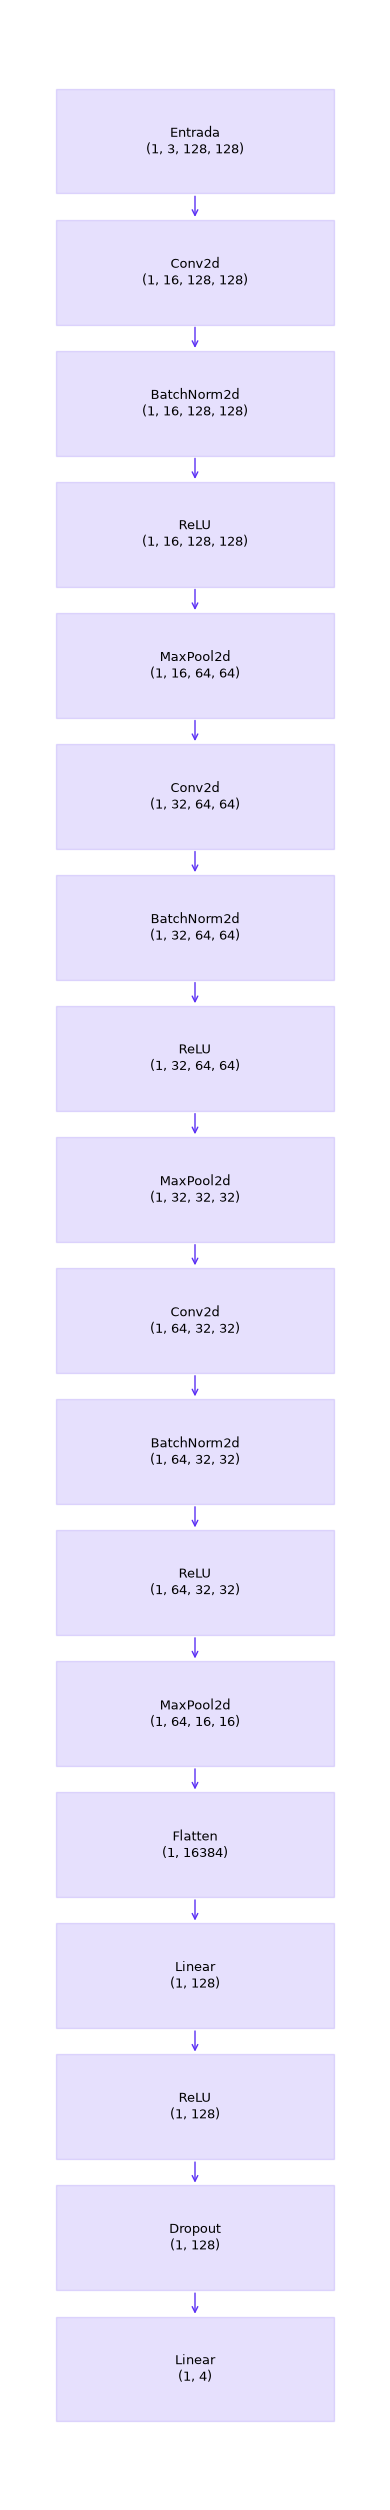

In [20]:
visualizar_modelo(model, input_shape=(3,128,128), nombre_archivo='model.png')

## Compilación y entrenamiento del modelo.

In [21]:
# 1. Crear los DataLoaders para organizar los datos en lotes (batches)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"DataLoaders listos: {len(train_loader)} lotes de entrenamiento, {len(val_loader)} lotes de validación.")

# 2. Instanciar el modelo y enviarlo al dispositivo (GPU o CPU)
seed_everything(SEED)
model = load_model().to(device)

# 3. Definir el optimizador y la función de pérdida
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0003)

# 4. Ejecutar el entrenamiento (por n épocas)
history_m1 = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    epochs=9,
    criterion=criterion,
    device=device
)

DataLoaders listos: 154 lotes de entrenamiento, 33 lotes de validación.
Epoch 1/9 - loss: 0.6362 - accuracy: 0.7451 - val_loss: 0.4191 - val_accuracy: 0.8338
Epoch 2/9 - loss: 0.3798 - accuracy: 0.8529 - val_loss: 0.3499 - val_accuracy: 0.8519
Epoch 3/9 - loss: 0.3059 - accuracy: 0.8806 - val_loss: 0.3393 - val_accuracy: 0.8689
Epoch 4/9 - loss: 0.2419 - accuracy: 0.9093 - val_loss: 0.3009 - val_accuracy: 0.8813
Epoch 5/9 - loss: 0.2040 - accuracy: 0.9272 - val_loss: 0.3123 - val_accuracy: 0.8946
Epoch 6/9 - loss: 0.1482 - accuracy: 0.9487 - val_loss: 0.1956 - val_accuracy: 0.9307
Epoch 7/9 - loss: 0.1238 - accuracy: 0.9536 - val_loss: 0.2382 - val_accuracy: 0.9136
Epoch 8/9 - loss: 0.1110 - accuracy: 0.9593 - val_loss: 0.1805 - val_accuracy: 0.9383
Epoch 9/9 - loss: 0.0754 - accuracy: 0.9744 - val_loss: 0.1724 - val_accuracy: 0.9468


## Graficar curvas de precisión pérdida.

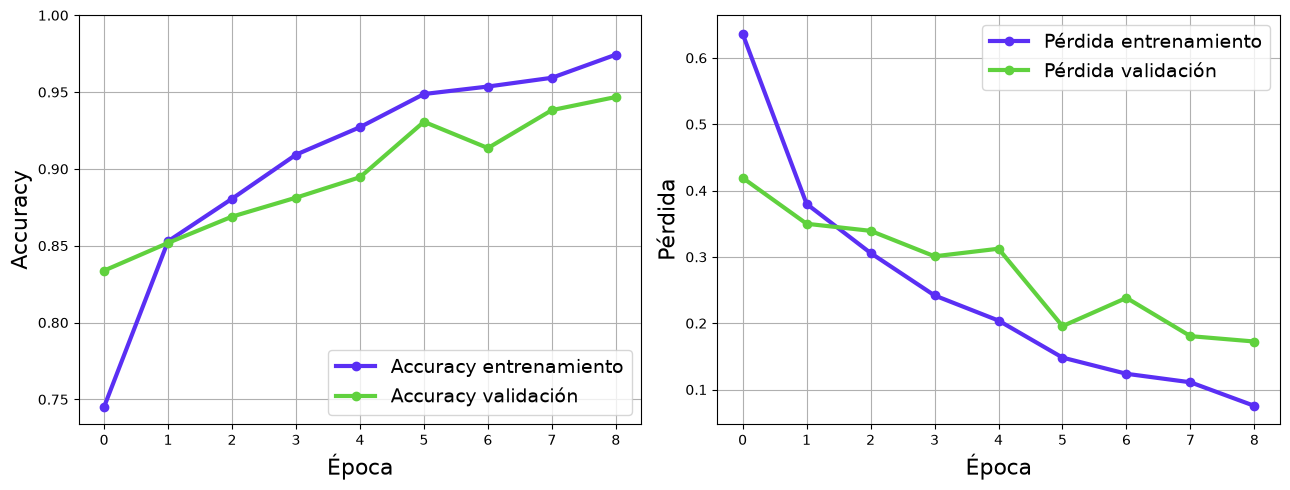

In [22]:
# Llamado a la función de visualización de las métricas de la historia del entrenamiento
# del modelo, en la prrimera gráfica se presenta la precisión y en la segunda la pérdida
visualization_history(history_m1)

## Generación matriz de confusión para visualizar el desempeño del modelo en la clasificación  de imágenes por categoria en conjunto de prueba.

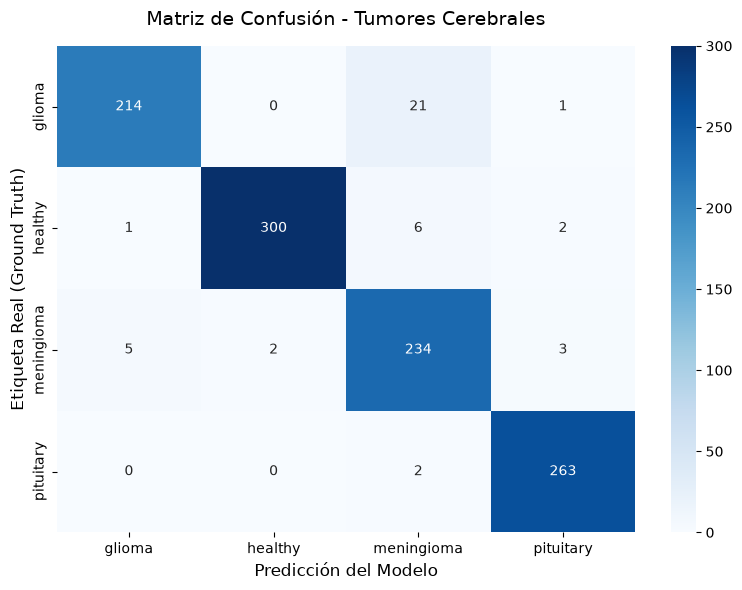


--- Reporte de Clasificación Detallado ---
              precision    recall  f1-score   support

      glioma       0.97      0.91      0.94       236
     healthy       0.99      0.97      0.98       309
  meningioma       0.89      0.96      0.92       244
   pituitary       0.98      0.99      0.99       265

    accuracy                           0.96      1054
   macro avg       0.96      0.96      0.96      1054
weighted avg       0.96      0.96      0.96      1054



In [23]:
# Ejecutar la evaluación con el modelo y el test_loader
resultados_m1 = evaluate_and_report_model(model, test_loader, device, class_names)

## Análisis de resultados y conclusiones.


### Análisis de las Curvas de exactitud y pérdida.

El proceso de entrenamiento de la Red Neuronal Convolucional se fijó en un total de $9$ épocas, número confirmado con el conjunto de validación. A partir de las gráficas de evolución, se desprenden las siguientes observaciones clave:
* **Comportamiento de la exactitud:** La exactitud de entrenamiento mostró un incremento constante desde un $74.5\%$ inicial hasta alcanzar un $97.4\%$. Por su parte, la exactitud de validación ascendió desde un $83.4\%$ hasta un $94.7\%$ en la última época, con una oscilación en la época $7$, reflejando una buena capacidad de generalización del modelo frente a datos no vistos previamente.
* **Función de pérdida (*Loss*):** La pérdida de entrenamiento descendió de forma constante de $0.64$ a $0.08$. La pérdida de validación bajó de $0.42$ a $0.17$, con un repunte puntual en la época $7$ ($0.24$), y alcanzó su mínimo en la última época, por lo que no se observan signos de sobreajuste (*overfitting*) en las $9$ épocas de entrenamiento.

### Desempeño Cuantitativo y Discriminación por Clases
La evaluación sobre el conjunto de prueba ($1054$ imágenes) arrojó una **exactitud global (*accuracy*) del $95.9\%$**, con un F1 macro de $0.96$. El análisis detallado por clase demuestra:
* **Clases con mejor desempeño:** Las categorías de tumores hipofisarios (*pituitary*, $F1 = 0.99$) y tejido sano (*healthy*, $F1 = 0.98$) presentaron el mejor rendimiento. Su recall ($0.99$ y $0.97$, respectivamente) ratifica que son mínimos los casos reales de estas clases que son clasificados erradamente por el modelo, disminuyendo el riesgo de falsos negativos en dichos diagnósticos.
* **Clases con mayor dificultad:** Las categorías de *glioma* ($F1 = 0.94$) y especialmente *meningioma* ($F1 = 0.92$). El bajo recall del glioma ($0.91$) frente a su alta precisión ($0.97$) indica que una parte de los gliomas se asigna a otras clases, principalmente a meningioma ($21$ de $236$), lo que sugiere solapamientos visuales entre ambas clases; por ello la precisión del meningioma es la más baja ($0.89$).

### Conclusiones Principales
1. **Eficacia del enfoque propuesto:** La arquitectura modular diseñada (compuesta por tres bloques convolucionales con *BatchNorm*, capas de reducción y regularización por *Dropout* con $p=0.3$) demostró ser eficaz para la clasificación multiclase de resonancias magnéticas cerebrales, alcanzando un $95.9\%$ de exactitud con $2,121,604$ parámetros entrenables.
2. **Eficiencia computacional:** El uso de imágenes bidimensionales individuales y un entrenamiento de solo $9$ épocas valida que es posible obtener una exactitud alta sin necesidad de recurrir a arquitecturas hiperparametrizadas o volúmenes tridimensionales completos que incrementen desproporcionadamente el costo computacional.
3. **Potencial de aplicación:** Los resultados obtenidos posicionan al modelo desarrollado como una herramienta automatizada de apoyo al diagnóstico médico, con potencial para optimizar los tiempos de triaje clínico en entornos hospitalarios.

A continuación se crean dos arquitecturas utilizando la red pre-entrenada púbica ResNet 18. La primer arquitectura mantiene congelados los parámetros de la red pre-entrenada y entrena solo el clasificador personal que se adiciona al final, mientras que la segunda arquitectura descongela las capas finales de la red pre-entrenada y se realiza un fine-tunning sobre las mismas:

<a id="seccion-4"></a>
# 4. Utilización de red pre-entrenada:

In [24]:
def get_feature_extractor_model():
  # 1. Cargar el modelo pre-entrenado (usamos ResNet18)
  model_pre1 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

  # 2. Congelar TODOS los parámetros de las capas base (extractor de características)
  for param in model_pre1.parameters():
    param.requires_grad = False

  # 3. Reemplazar la capa fully connected (fc) por clasificador personalizado.
  # Se adicionan las mismas capas linear del modelo inicial.
  # Por defecto, los módulos nuevos que se adicionan aquí (nn.Linear) tendrán requires_grad = True automáticamente.
  # Obtener cuántas características bajan de la red pre-entrenada (para ResNet18 es 512)
  num_ftrs = model_pre1.fc.in_features
  model_pre1.fc = nn.Sequential(
      nn.Linear(num_ftrs, 128),  # Capa densa intermedia. Entra con 512 (lo de ResNet) y transforma a 128
      nn.ReLU(),
      nn.Dropout(p=0.3),  # Regularización coherente con el modelo inicial.
      nn.Linear(128, 4),  # Capa de salida para las 4 clases de tumores
  )

  return model_pre1


### Resumen del modelo.

### Compilación y entrenamiento del modelo

In [25]:
# 1. Crear los DataLoaders para organizar los datos en lotes (batches)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(
    f"DataLoaders listos: {len(train_loader)} lotes de entrenamiento,"
    f" {len(val_loader)} lotes de validación."
)

# 2. Instanciar el modelo pre-entrenado sin fine-tunning y enviarlo al dispositivo (GPU o CPU)
seed_everything(SEED)
model_pre_sft = get_feature_extractor_model().to(device)

# 3. Definir la función de pérdida y el optimizador (¡Atención aquí!)
criterion = nn.CrossEntropyLoss()

# Utilizamos el mismo optimizador del modelo inicial con capas convolucionales
# Usamos filter para que Adam solo optimice las capas que tienen requires_grad = True
# (es decir, el clasificador nuevo, ignorando las capas de la red pre-entrenada)
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model_pre_sft.parameters()), lr=0.001
)

# 4. Ejecutar el entrenamiento (por n épocas)
history_m2 = train_model(
    model=model_pre_sft,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    epochs=8,
    criterion=criterion,
    device=device,
)

DataLoaders listos: 154 lotes de entrenamiento, 33 lotes de validación.
Epoch 1/8 - loss: 0.6300 - accuracy: 0.7596 - val_loss: 0.4847 - val_accuracy: 0.8101
Epoch 2/8 - loss: 0.4427 - accuracy: 0.8330 - val_loss: 0.4118 - val_accuracy: 0.8452
Epoch 3/8 - loss: 0.3718 - accuracy: 0.8609 - val_loss: 0.3560 - val_accuracy: 0.8623
Epoch 4/8 - loss: 0.3370 - accuracy: 0.8704 - val_loss: 0.3547 - val_accuracy: 0.8651
Epoch 5/8 - loss: 0.3125 - accuracy: 0.8784 - val_loss: 0.3185 - val_accuracy: 0.8775
Epoch 6/8 - loss: 0.2853 - accuracy: 0.8938 - val_loss: 0.3548 - val_accuracy: 0.8689
Epoch 7/8 - loss: 0.2633 - accuracy: 0.9009 - val_loss: 0.2995 - val_accuracy: 0.8727
Epoch 8/8 - loss: 0.2531 - accuracy: 0.8999 - val_loss: 0.2796 - val_accuracy: 0.8908


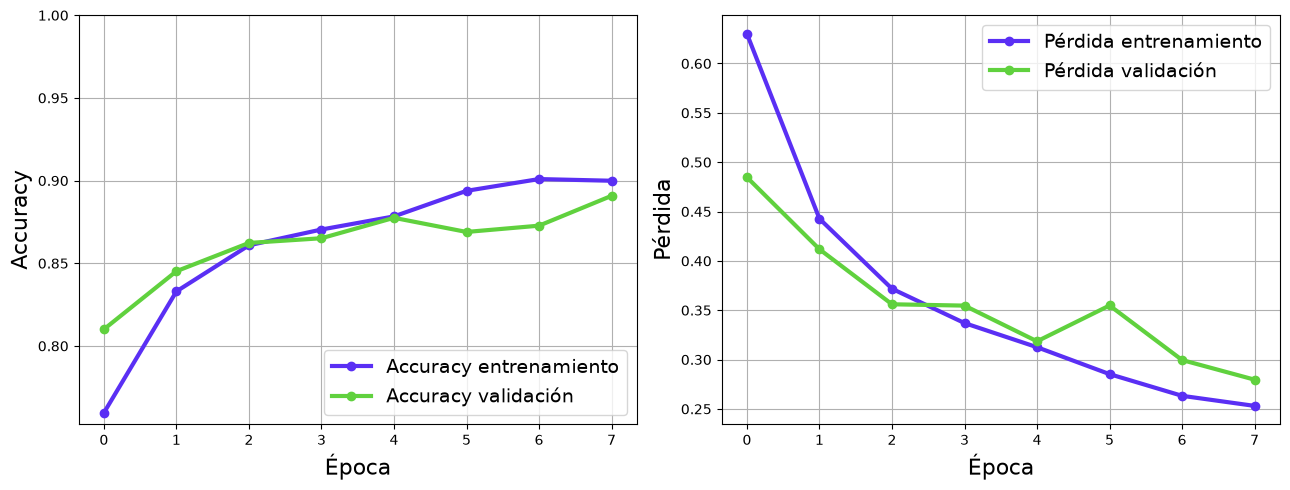

In [26]:
visualization_history(history_m2)

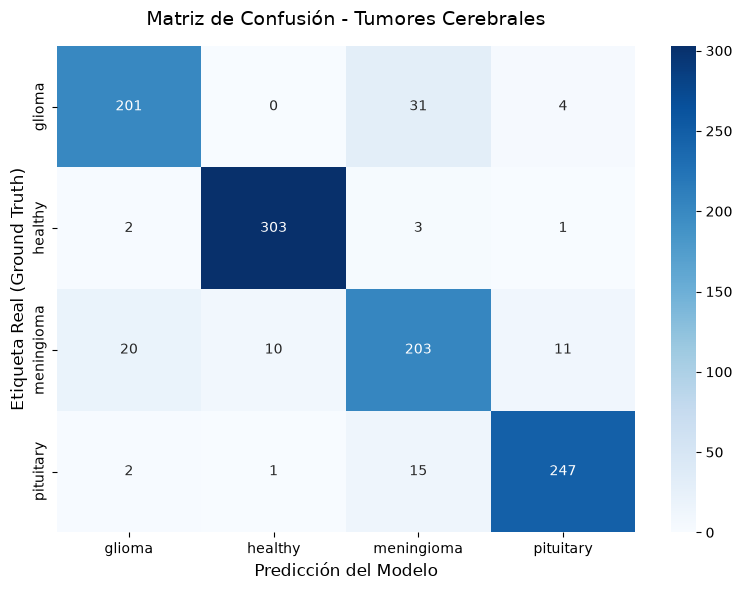


--- Reporte de Clasificación Detallado ---
              precision    recall  f1-score   support

      glioma       0.89      0.85      0.87       236
     healthy       0.96      0.98      0.97       309
  meningioma       0.81      0.83      0.82       244
   pituitary       0.94      0.93      0.94       265

    accuracy                           0.91      1054
   macro avg       0.90      0.90      0.90      1054
weighted avg       0.91      0.91      0.91      1054



In [27]:
resultados_m2 = evaluate_and_report_model(model_pre_sft, test_loader, device, class_names)

### Análisis de resultados:
- La exactitud de entrenamiento muestra un crecimiento sostenido desde un $76.0\%$ inicial hasta alcanzar el $90.0\%$ en la última época. Por su parte, la exactitud de validación parte de un valor base de $81.0\%$ (gracias al conocimiento previo de ResNet) y asciende hasta el $89.1\%$, muy cercana a la de entrenamiento, lo que indica ausencia de sobreajuste, pero también una capacidad de aprendizaje limitada (sesgo alto) al mantener congelado el tronco convolucional.
- Ambas curvas de pérdida descienden hacia las épocas finales. La pérdida de entrenamiento desciende desde $0.63$ hasta $0.25$, mientras que la de validación disminuye desde $0.48$ hasta $0.28$, y aún seguía bajando en la última época.
- El modelo alcanzó una exactitud global (accuracy) del $90.5\%$, con un F1 macro de $0.90$, inferior al del modelo base de capas convolucionales, que alcanzó un $95.9\%$ de exactitud y un F1 macro de $0.96$.
- Las métricas por clase (F1-Score) son inferiores a las del modelo base de capas convolucionales en glioma ($0.87$ frente a $0.94$), meningioma ($0.82$ frente a $0.92$), pituitary ($0.94$ frente a $0.99$) y healthy ($0.97$ frente a $0.98$).
- De lo anterior se concluye que el modelo básico presenta un mejor rendimiento que el modelo con red pre-entrenada sin fine-tuning.

<a id="seccion-5"></a>
# 5. Utilización de red pre-entrenada con fine-tunning.

A continuación realizamos el fine-tunnig sobre el último bloque convolucional de la red pre-entrenada

In [28]:
# Identificar el nombre de las capas de la red
resnet_base  = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
print(resnet_base)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [29]:

def get_finetuned_resnet_model():
  # 1. Cargar ResNet18 con pesos pre-entrenados
  model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

  # 2. Congelar toda la red inicialmente
  for param in model.parameters():
    param.requires_grad = False

  # 3. Descongelar el último bloque convolucional (layer4)
  # Esto permite adaptar las características de alto nivel a las imágenes médicas de tumores
  for param in model.layer4.parameters():
    param.requires_grad = True

  # 4. Reemplazar la capa fully connected (fc) por el clasificador personalizado
  # (Por defecto, los módulos nuevos que creamos aquí ya tienen requires_grad = True)
  num_ftrs = model.fc.in_features
  model.fc = nn.Sequential(
      nn.Linear(num_ftrs, 128),  # Capa densa intermedia
      nn.ReLU(),
      nn.Dropout(p=0.3),  # Regularización coherente
      nn.Linear(128, 4),  # Capa de salida para las 4 clases de tumores
  )

  return model



### Compliación y entrenamiento del modelo

In [30]:
# Instanciar el modelo de Fine-Tuning
seed_everything(SEED)
model_finetune = get_finetuned_resnet_model().to(device)
# Función de pérdida
criterion = nn.CrossEntropyLoss()

# Optimizador filtrando únicamente los parámetros que tienen requires_grad = True (layer4 + el clasificador)
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model_finetune.parameters()), lr=1e-4
)

# Ejecutar el entrenamiento del modelo con Fine-Tuning
history_finetune = train_model(
    model=model_finetune,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    epochs=5,
    criterion=criterion,
    device=device,
)

Epoch 1/5 - loss: 0.3998 - accuracy: 0.8600 - val_loss: 0.1882 - val_accuracy: 0.9326
Epoch 2/5 - loss: 0.1133 - accuracy: 0.9654 - val_loss: 0.1182 - val_accuracy: 0.9573
Epoch 3/5 - loss: 0.0517 - accuracy: 0.9860 - val_loss: 0.1228 - val_accuracy: 0.9582
Epoch 4/5 - loss: 0.0231 - accuracy: 0.9945 - val_loss: 0.1389 - val_accuracy: 0.9573
Epoch 5/5 - loss: 0.0196 - accuracy: 0.9951 - val_loss: 0.1222 - val_accuracy: 0.9677


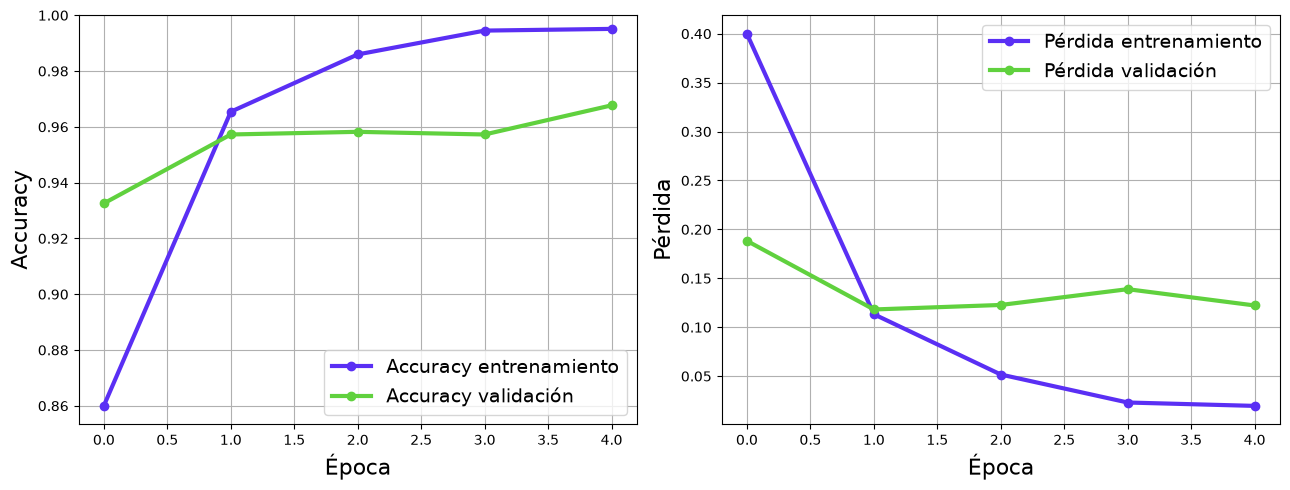

In [31]:
visualization_history(history_finetune)

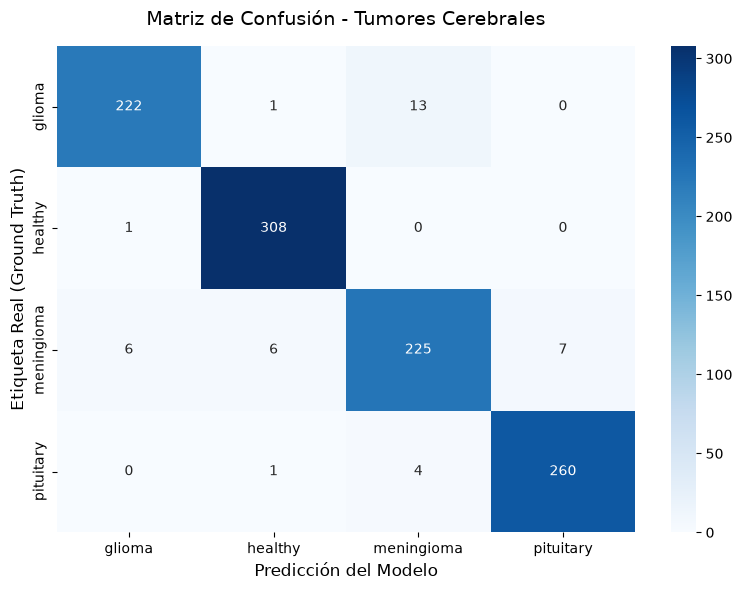


--- Reporte de Clasificación Detallado ---
              precision    recall  f1-score   support

      glioma       0.97      0.94      0.95       236
     healthy       0.97      1.00      0.99       309
  meningioma       0.93      0.92      0.93       244
   pituitary       0.97      0.98      0.98       265

    accuracy                           0.96      1054
   macro avg       0.96      0.96      0.96      1054
weighted avg       0.96      0.96      0.96      1054



In [32]:
resultados_m3 =  evaluate_and_report_model(model_finetune, test_loader, device, class_names)

### Generación grafica Grad CAM modelo fine-tunning

Aqui el siguiente código nos permite ver mendiante gradcam un ejemplo donde el modelo clasifica correctamente y otro donde no lo hizo bien:

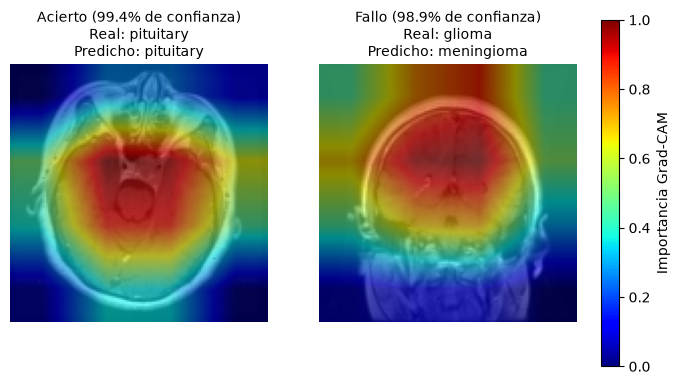

In [33]:
# 1. Buscar en el conjunto de prueba ejemplos donde el Modelo 3 acierta y donde falla
N_ACIERTOS, N_FALLOS = 1, 1
aciertos, fallos = [], []

model_finetune.eval()
with torch.no_grad():
    for images, labels in test_loader:
        probabilidades = torch.softmax(model_finetune(images.to(device)), dim=1).cpu()
        confianzas, predicciones = probabilidades.max(dim=1)
        for img, real, pred, conf in zip(images, labels, predicciones, confianzas):
            real, pred = real.item(), pred.item()
            ejemplo = (img, real, pred, conf.item() * 100)
            if pred == real and len(aciertos) < N_ACIERTOS:
                aciertos.append(ejemplo)
            elif pred != real and len(fallos) < N_FALLOS:
                fallos.append(ejemplo)
        if len(aciertos) == N_ACIERTOS and len(fallos) == N_FALLOS:
            break

ejemplos = aciertos + fallos

# 2. Generar Grad-CAM sobre el último bloque de layer4, para la clase que predijo el modelo
fig, axes = plt.subplots(1, len(ejemplos), figsize=(4 * len(ejemplos), 4.5))
axes = np.atleast_1d(axes)

with GradCAM(model=model_finetune, target_layers=[model_finetune.layer4[-1]]) as cam:
    for ax, (img, real, pred, conf) in zip(axes, ejemplos):
        mapa = cam(input_tensor=img.unsqueeze(0).to(device), targets=[ClassifierOutputTarget(pred)])[0]
        superpuesta = show_cam_on_image(img.permute(1, 2, 0).numpy(), mapa, use_rgb=True)
        ax.imshow(superpuesta)
        resultado = "Acierto" if pred == real else "Fallo"
        ax.set_title(f"{resultado} ({conf:.1f}% de confianza)\nReal: {class_names[real]}\nPredicho: {class_names[pred]}",
                     fontsize=10)
        ax.axis("off")

# 3. Barra de color (show_cam_on_image usa el mapa de color JET)
barra = plt.cm.ScalarMappable(cmap="jet", norm=plt.Normalize(0, 1))
fig.colorbar(barra, ax=axes.tolist(), fraction=0.046, pad=0.04, label="Importancia Grad-CAM")

plt.savefig("gradcam_aciertos_fallos.png", bbox_inches="tight", dpi=300)
plt.show()

Validación de confianza con Grad-CAM:
La figura anterior muestra un acierto y un fallo del Modelo 3 (Fine-Tuning) sobre el conjunto de prueba. En el acierto, para una instancia de la clase *pituitary*, el modelo emitió una predicción correcta con un $99.4\%$ de confianza y concentró sus activaciones (tonalidades cálidas) en la región central, próxima a la zona selar, aunque el mapa es difuso por su baja resolución ($4\times4$ en `layer4`). En el fallo, un *glioma* fue clasificado como *meningioma* con un $98.9\%$ de confianza, con activaciones en el borde del cráneo y fuera del tejido tumoral. Esto evidencia que una confianza alta no garantiza una predicción correcta.

- El modelo inicia en la época 1 con un desempeño sobresaliente del $93.3\%$ en validación, acelerando rápidamente hasta alcanzar el $99.5\%$ en entrenamiento y un $96.8\%$ en validación en la época 5.

-  La pérdida de entrenamiento experimenta un descenso drástico desde $0.40$ hasta $0.020$. En el conjunto de validación, alcanza su punto mínimo en la época 2 ($0.118$) y luego oscila entre $0.12$ y $0.14$, lo que, junto con la brecha entre entrenamiento y validación, indica un leve sobreajuste.

- Desempeño por clase (conjunto de prueba, exactitud global del $96.3\%$):

- Glioma: Alcanza una precisión del $97\%$ y un Recall del $94\%$ ($F1=0.95$).

- Healthy: Excelente generalización con precisión del $97\%$ y Recall del $100\%$ ($F1=0.99$).

- Meningioma: Mejora notablemente el desempeño de clasificación de esta clase frente al Modelo 2, con un Recall del $92\%$ y una precisión del $93\%$ ($F1=0.93$).

- Pituitary: Rendimiento casi perfecto con precisión del $97\%$ y Recall del $98\%$ ($F1=0.98$).

<a id="seccion-6"></a>
# 6. Tabla Comparativa de resultados de los tres modelos:

In [34]:
# Reunir el modelo, su historial de validacion y sus resultados con el conjunto test
modelos = {
    "Modelo 1: CNN personalizada": (model, history_m1, resultados_m1),
    "Modelo 2: ResNet18 Base": (model_pre_sft, history_m2, resultados_m2),
    "Modelo 3: ResNet18 con fine-tuning": (model_finetune, history_finetune, resultados_m3),
}

filas = {}
for nombre, (modelo, historial, resultados) in modelos.items():
    fila = {
        "Parámetros entrenables": sum(p.numel() for p in modelo.parameters() if p.requires_grad),
        "Épocas": len(historial["val_accuracy"]),
        "Exactitud validación": historial["val_accuracy"][-1],
        "Pérdida validación": historial["val_loss"][-1],
        "Exactitud prueba": resultados["accuracy"],
        "F1 macro prueba": resultados["macro avg"]["f1-score"],
    }
    for clase in class_names:
        fila[f"F1 {clase} prueba"] = resultados[clase]["f1-score"]
    filas[nombre] = fila

df_comparativa = pd.DataFrame.from_dict(filas, orient="index")
display(df_comparativa.round(4))

# El mejor modelo se elige con respecto al conjunto de validación
mejor_modelo = df_comparativa["Exactitud validación"].idxmax()
print(f"Mejor modelo según el conjunto de validación: {mejor_modelo}")

,Parámetros entrenables,Épocas,Exactitud validación,Pérdida validación,Exactitud prueba,F1 macro prueba,F1 glioma prueba,F1 healthy prueba,F1 meningioma prueba,F1 pituitary prueba
Modelo 1: CNN personalizada,2121604,9,0.9468,0.1724,0.9592,0.9572,0.9386,0.9820,0.9231,0.9850
Modelo 2: ResNet18 Base,66180,8,0.8908,0.2796,0.9051,0.8997,0.8720,0.9727,0.8185,0.9356
Modelo 3: ResNet18 con fine-tuning,8459908,5,0.9677,0.1222,0.9630,0.9610,0.9548,0.9856,0.9259,0.9774


Mejor modelo según el conjunto de validación: Modelo 3: ResNet18 con fine-tuning


<a id="seccion-7"></a>
# 7. Conclusiones:

- A pesar de haber sido entrenado desde cero sobre un volumen limitado de datos y con una arquitectura significativamente más simple que ResNet18, el Modelo 1 alcanzó un $95.9\%$ de exactitud global. Esto supera al modelo de Feature Extraction puro ($90.5\%$) y demuestra que el diseño del extractor de características convolucionales (bloques de convolución, BatchNorm, activación ReLU, Max Pooling y Dropout) fue apropiado para capturar las particularidades visuales de las resonancias magnéticas.

- En cuanto al costo computacional, el Modelo base requirió más épocas ($9$) para moldear sus filtros partiendo de parámetros aleatorios. En contraste, el Modelo 3 (Fine-Tuning) aprovechó la representación previa de ImageNet, requiriendo solo $5$ épocas para reajustar su bloque convolucional superior (layer4) y lograr el mejor rendimiento global ($96.3\%$).

- En cuanto a la capacidad de clasificación por clases, la red personalizada convolucional demostró ser un modelo sólido (especialmente en Pituitary con $0.99$ y Healthy con $0.98$). Sin embargo, presentó una menor sensibilidad en Glioma ($F1=0.94$, recall de $0.91$) frente a la capacidad representacional superior del bloque convolucional adaptado de ResNet18 ($F1=0.95$).

- En conclusión, el Modelo base personalizado de capas convolucionales se valida como una solución liviana, interpretable y eficaz para entornos con restricciones de hardware donde no se pueda desplegar una red pre-entrenada pesada, mientras que el Modelo con Fine-Tuning (ResNet18 + layer4) se consagra como la arquitectura de mayor exactitud ($96.3\%$) al combinar transferencia de conocimiento base con especialización médica de alto nivel.

Autores:

Jhon Edward Zacipa Casas, Id estudiante: 202613383

José Luis Sarta Alvarez, Id estudiante: 202612984

Marco Julio Gómez Amado, Id estudiante: 199918013